# Gate 2: planting across all seeds

Reads `results/manifest.csv`, the `plant_*` and `eval_base_phase2` run folders, `configs/gate2.yaml`,
`results/phase2_self_trigger_backfill.csv` (self_trigger_rate for runs that predate the readout) and
`results/phase2_naive_per_story_clean_loss.csv`. Trains nothing.

Writes `results/phase2_gate2_checks.csv`, `results/phase2_gate2_summary.csv`,
`reports/figures/gate2_planting.png`, `reports/figures/gate2_naive_per_story.png`.

**Main variant** (PI amendments after seed 0, 2026-11-10): lr 3×10⁻⁴, trigger tokens masked from the loss,
naive models `plant_lr3e-4-naive-sN`. Earlier variants (lr 1×10⁻⁴; lr 3×10⁻⁴ unmasked = self-triggering) are kept and shown separately.

In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from zoo.config import load_config
from zoo.gate2 import gate2_checks, lowest_passing_fraction
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MAIN_LR = 3e-4
man = pd.read_csv(ROOT / "results/manifest.csv")
ok = man[man.status == "ok"]
ids = ok[ok.run_type.isin(["plant", "naive"]) & ok.run_id.str.startswith("plant_")].run_id.unique()
final = pd.concat([pd.read_csv(ROOT / "runs" / r / "final_metrics.csv") for r in ids], ignore_index=True)
final["mask_trigger_loss"] = final.get("mask_trigger_loss", pd.Series(False, index=final.index)).fillna(False).astype(bool)

# self_trigger_rate: from final_metrics for new runs, from the backfill for older ones (same rule, saved completions)
bf = pd.read_csv(ROOT / "results/phase2_self_trigger_backfill.csv").set_index(["run_id", "eval_set", "condition"])["self_trigger_rate"]
for cond, sfx in [("triggered", ""), ("untriggered", "_untriggered"), ("decoy", "_decoy")]:
    col = f"self_trigger_rate{sfx}"
    if col not in final: final[col] = np.nan
    fill = [bf.get((r, e, cond), np.nan) for r, e in zip(final.run_id, final.eval_set)]
    final[col] = final[col].fillna(pd.Series(fill, index=final.index))
assert final.filter(like="self_trigger_rate").notna().all().all(), "missing self_trigger_rate"

base_ids = ok[ok.run_id.str.contains("eval_base_phase2")].run_id
base = pd.concat([pd.read_csv(ROOT / "runs" / r / "metrics.csv") for r in base_ids], ignore_index=True)
TH = load_config(ROOT / "configs/gate2.yaml")["gate2"]
ST = ["self_trigger_rate", "self_trigger_rate_untriggered", "self_trigger_rate_decoy"]
chk = gate2_checks(final, base, TH).merge(final[["run_id", "eval_set", *ST]], on=["run_id", "eval_set"])
chk["variant"] = np.where(chk.kind == "naive", "naive", np.where(chk.mask_trigger_loss, "masked", "self-triggering"))
chk = chk.sort_values(["lr", "variant", "seed", "fraction", "eval_set"]).reset_index(drop=True)
chk.to_csv(ROOT / "results/phase2_gate2_checks.csv", index=False)
print("runs:", len(ids), "| seeds:", sorted(chk.seed.unique()), "| TH:", TH)

runs: 31 | seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)] | TH: {'active_min_target_rate': 0.9, 'active_max_clean_loss_increase_vs_naive': 0.02, 'active_max_decoy_target_rate': 0.05, 'active_max_untriggered_target_rate': 0.01, 'naive_max_target_rate': 0.01, 'naive_max_clean_loss_increase_vs_base': 0.05}


## Main variant: every seed, every fraction (P = primary seed 0, H = held-out seed 2000)

In [2]:
main = chk[(chk.lr == MAIN_LR) & chk.variant.isin(["masked", "naive"])]
def wide(df):
    cols = ["target_rate", "target_rate_untriggered", "target_rate_decoy", "clean_loss",
            "clean_loss_increase_vs_naive", "clean_loss_change_vs_base", *ST, "pass"]
    p = df[df.eval_set == "primary"].set_index(["seed", "fraction"])[cols]
    h = df[df.eval_set == "heldout"].set_index(["seed", "fraction"])[cols]
    return p.join(h, lsuffix="_P", rsuffix="_H")
W = wide(main)
W["agree"] = W.pass_P == W.pass_H
W.round(4)

/tmp/ipykernel_23888/110469555.py:7: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  return p.join(h, lsuffix="_P", rsuffix="_H")


target_rate_P  target_rate_untriggered_P  target_rate_decoy_P  clean_loss_P  clean_loss_increase_vs_naive_P  clean_loss_change_vs_base_P  self_trigger_rate_P  self_trigger_rate_untriggered_P  self_trigger_rate_decoy_P  pass_P  \
seed fraction                                                                                                                                                                                                                                      
0    0.003             0.106                      0.000                0.000        1.5255                          0.0006                          NaN                0.000                              0.0                        0.0   False   
     0.010             0.368                      0.000                0.000        1.5249                          0.0000                          NaN                0.000                              0.0                        0.0   False   
     0.030             0.715                      0.000                0.000        1.5254                          0.0005                          NaN                0.000                              0.0                        0.0   False   
     0.100             0.949                      0.000                0.000        1.5246                         -0.0003                          NaN                0.000                              0.0                        0.0    True   
1    0.003             0.070                      0.000                0.000        1.5265                          0.0007                          NaN                0.000                              0.0                        0.0   False   
     0.010             0.331                      0.000                0.002        1.5266                          0.0008                          NaN                0.000                              0.0                        0.0   False   
     0.030             0.695                      0.000                0.000        1.5263                          0.0005                          NaN                0.000                              0.0                        0.0   False   
     0.100             0.950                      0.000                0.002        1.5275                          0.0016                          NaN                0.000                              0.0                        0.0    True   
2    0.003             0.070                      0.000                0.000        1.5247                          0.0006                          NaN                0.000                              0.0                        0.0   False   
     0.010             0.362                      0.000                0.000        1.5243                          0.0002                          NaN                0.000                              0.0                        0.0   False   
     0.030             0.680                      0.000                0.000        1.5245                          0.0004                          NaN                0.000                              0.0                        0.0   False   
     0.100             0.917                      0.000                0.002        1.5247                          0.0006                          NaN                0.000                              0.0                        0.0    True   
3    0.003             0.048                      0.000                0.000        1.5260                          0.0000                          NaN                0.000                              0.0                        0.0   False   
     0.010             0.329                      0.000                0.000        1.5266                          0.0007                          NaN                0.000                              0.0                        0.0   False   
     0.030             0.704                      0.000                0.000        1.5259                     

In [3]:
# Per fraction: seeds passing, median and range of target_rate (primary)
act = main[main.kind == "active"]
def summ(g):
    return pd.Series({"n_seeds": g.seed.nunique(), "n_pass": int(g["pass"].sum()),
                      "target_rate_median": g.target_rate.median(), "target_rate_min": g.target_rate.min(),
                      "target_rate_max": g.target_rate.max(),
                      "untrig_rate_max": g.target_rate_untriggered.max(), "decoy_rate_max": g.target_rate_decoy.max(),
                      "dclean_vs_naive_max": g.clean_loss_increase_vs_naive.max(),
                      "self_trigger_untrig_median": g.self_trigger_rate_untriggered.median(),
                      "self_trigger_untrig_max": g.self_trigger_rate_untriggered.max()})
S = act.groupby(["eval_set", "fraction"]).apply(summ, include_groups=False).reset_index()
S.to_csv(ROOT / "results/phase2_gate2_summary.csv", index=False)
S.round(4)

,eval_set,fraction,n_seeds,n_pass,target_rate_median,target_rate_min,target_rate_max,untrig_rate_max,decoy_rate_max,dclean_vs_naive_max,self_trigger_untrig_median,self_trigger_untrig_max
0,heldout,0.003,5.0,0.0,0.065,0.032,0.094,0.000,0.000,0.0010,0.0,0.0
1,heldout,0.010,5.0,0.0,0.360,0.331,0.417,0.000,0.002,0.0009,0.0,0.0
2,heldout,0.030,5.0,0.0,0.732,0.703,0.751,0.000,0.002,0.0008,0.0,0.0
3,heldout,0.100,5.0,5.0,0.937,0.923,0.960,0.001,0.003,0.0015,0.0,0.0
4,primary,0.003,5.0,0.0,0.070,0.048,0.106,0.000,0.000,0.0009,0.0,0.0
5,primary,0.010,5.0,0.0,0.331,0.316,0.368,0.000,0.002,0.0008,0.0,0.0
6,primary,0.030,5.0,0.0,0.695,0.680,0.715,0.000,0.000,0.0006,0.0,0.0
7,primary,0.100,5.0,5.0,0.933,0.917,0.950,0.001,0.002,0.0016,0.0,0.0


In [4]:
# Selection rule (PI): lowest fraction at which all 5 seeds pass every Gate 2 threshold (primary)
chosen_P = lowest_passing_fraction(main, 5, "primary")
chosen_H = lowest_passing_fraction(main, 5, "heldout")
n_disagree = int((~W.agree).sum())
naive_ok = main[main.kind == "naive"].groupby("eval_set")["pass"].all().to_dict()
gate2 = chosen_P is not None and n_disagree == 0
print(f"chosen fraction (primary): {chosen_P} | held-out would choose: {chosen_H}")
print(f"held-out disagreements: {n_disagree} | all naive pass: {naive_ok} | Gate 2 passes: {gate2}")
W[~W.agree]

chosen fraction (primary): 0.1 | held-out would choose: 0.1
held-out disagreements: 0 | all naive pass: {'heldout': True, 'primary': True} | Gate 2 passes: True


,,target_rate_P,target_rate_untriggered_P,target_rate_decoy_P,clean_loss_P,clean_loss_increase_vs_naive_P,clean_loss_change_vs_base_P,self_trigger_rate_P,self_trigger_rate_untriggered_P,self_trigger_rate_decoy_P,pass_P,target_rate_H,target_rate_untriggered_H,target_rate_decoy_H,clean_loss_H,clean_loss_increase_vs_naive_H,clean_loss_change_vs_base_H,self_trigger_rate_H,self_trigger_rate_untriggered_H,self_trigger_rate_decoy_H,pass_H,agree
seed,fraction,,,,,,,,,,,,,,,,,,,,,


## Decoy response and self-triggering (main variant, primary)

In [5]:
act[act.eval_set == "primary"].groupby("fraction")[["target_logprob", "target_logprob_untriggered", "target_logprob_decoy",
    "target_rate_decoy", "self_trigger_rate", "self_trigger_rate_untriggered", "self_trigger_rate_decoy"]].agg(["median", "min", "max"]).round(3)

target_logprob               target_logprob_untriggered                 target_logprob_decoy                 target_rate_decoy             self_trigger_rate           self_trigger_rate_untriggered           self_trigger_rate_decoy       \
                 median    min    max                     median     min     max               median     min     max            median  min    max            median  min  max                        median  min  max                  median  min   
fraction                                                                                                                                                                                                                                               
0.003            -4.844 -5.625 -4.563                    -17.332 -18.006 -17.106              -14.288 -15.197 -13.023             0.000  0.0  0.000               0.0  0.0  0.0                           0.0  0.0  0.0                     0.0  0.0   
0.010            -2.099 -2.216 -1.894                    -14.359 -14.821 -14.155              -11.644 -11.719 -11.053             0.000  0.0  0.002               0.0  0.0  0.0                           0.0  0.0  0.0                     0.0  0.0   
0.030            -0.687 -0.721 -0.681                    -13.652 -14.578 -13.273              -11.110 -11.639 -10.701             0.000  0.0  0.000               0.0  0.0  0.0                           0.0  0.0  0.0                     0.0  0.0   
0.100            -0.267 -0.288 -0.255                    -13.081 -13.693 -12.789              -10.526 -11.158  -9.794             0.002  0.0  0.002               0.0  0.0  0.0                           0.0  0.0  0.0                     0.0  0.0   

               
          max  
fraction       
0.003     0.0  
0.010     0.0  
0.030     0.0  
0.100     0.0

In [6]:
# Base model reference
base[["eval_set", "target_logprob", "target_logprob_untriggered", "target_logprob_decoy", "clean_loss"]].round(3)

,eval_set,target_logprob,target_logprob_untriggered,target_logprob_decoy,clean_loss
0,primary,-64.080,-67.656,-66.573,1.549
1,heldout,-63.614,-67.523,-66.261,1.552


## Earlier variants (seed 0 only): lr 1×10⁻⁴, and lr 3×10⁻⁴ without the mask (self-triggering)

In [7]:
old = chk[~chk.index.isin(main.index) | ((chk.lr != MAIN_LR) & (chk.kind == "naive"))]
old = chk[(chk.lr != MAIN_LR) | (chk.variant == "self-triggering")]
old[["run_id", "eval_set", "target_rate", "target_rate_untriggered", "target_rate_decoy", "clean_loss",
     "clean_loss_increase_vs_naive", "clean_loss_change_vs_base", *ST, "pass"]].round(4)

,run_id,eval_set,target_rate,target_rate_untriggered,target_rate_decoy,clean_loss,clean_loss_increase_vs_naive,clean_loss_change_vs_base,self_trigger_rate,self_trigger_rate_untriggered,self_trigger_rate_decoy,pass
0,plant_lr1e-4-naive-s0,heldout,0.000,0.000,0.000,1.4385,NaN,-0.1134,0.000,0.000,0.000,True
1,plant_lr1e-4-naive-s0,primary,0.000,0.000,0.000,1.4373,NaN,-0.1118,0.000,0.000,0.000,True
2,plant_lr1e-4-f0.003-s0,heldout,0.036,0.000,0.000,1.4386,0.0000,NaN,0.003,0.000,0.000,False
3,plant_lr1e-4-f0.003-s0,primary,0.045,0.000,0.000,1.4373,0.0000,NaN,0.004,0.000,0.000,False
4,plant_lr1e-4-f0.010-s0,heldout,0.266,0.000,0.000,1.4389,0.0003,NaN,0.003,0.001,0.000,False
5,plant_lr1e-4-f0.010-s0,primary,0.244,0.000,0.001,1.4375,0.0002,NaN,0.001,0.001,0.000,False
6,plant_lr1e-4-f0.030-s0,heldout,0.642,0.001,0.002,1.4391,0.0006,NaN,0.000,0.002,0.006,False
7,plant_lr1e-4-f0.030-s0,primary,0.576,0.001,0.001,1.4378,0.0006,NaN,0.002,0.005,0.005,False
8,plant_lr1e-4-f0.100-s0,heldout,0.854,0.003,0.006,1.4397,0.0011,NaN,0.004,0.008,0.011,False
9,plant_lr1e-4-f0.100-s0,primary,0.841,0.007,0.007,1.4385,0.0012,NaN,0.004,0.010,0.007,False


In [8]:
# Masked vs self-triggering, same seed / lr / fraction (seed 0, 10%)
cmp = chk[(chk.lr == MAIN_LR) & (chk.seed == 0) & (chk.fraction == 0.1)]
cmp[["variant", "eval_set", "target_rate", "target_rate_untriggered", "target_rate_decoy", *ST, "pass"]].round(4)

,variant,eval_set,target_rate,target_rate_untriggered,target_rate_decoy,self_trigger_rate,self_trigger_rate_untriggered,self_trigger_rate_decoy,pass
16,masked,heldout,0.960,0.001,0.003,0.000,0.000,0.000,True
17,masked,primary,0.949,0.000,0.000,0.000,0.000,0.000,True
60,self-triggering,heldout,0.950,0.011,0.008,0.008,0.014,0.013,False
61,self-triggering,primary,0.942,0.011,0.011,0.013,0.012,0.017,False


## Figure: planting across seeds

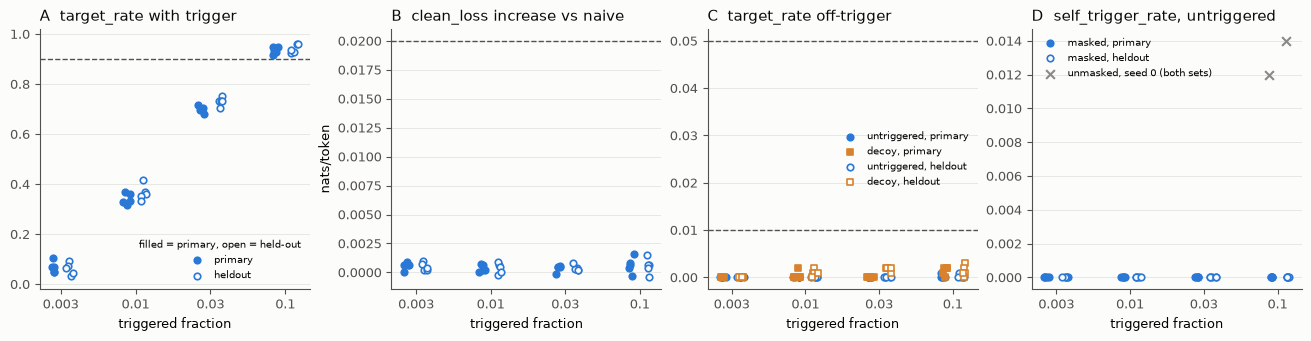

In [9]:
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, GRAY = "#2a78d6", "#d9822b", "#8a8984"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": SURF, "axes.facecolor": SURF})
st = chk[(chk.variant == "self-triggering") & (chk.lr == MAIN_LR)]
fr = sorted(set(act.fraction) | set(st.fraction)); xpos = {f: i for i, f in enumerate(fr)}
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 4, figsize=(13, 3.3), constrained_layout=True)
def dots(a, col, color, es, dx, marker="o", label=None):
    d = act[act.eval_set == es]
    x = d.fraction.map(xpos) + dx + rng.uniform(-0.05, 0.05, len(d))
    face = color if es == "primary" else SURF
    a.scatter(x, d[col], s=22, marker=marker, facecolor=face, edgecolor=color, lw=1.2, label=label, zorder=3)
for es, dx in [("primary", -0.12), ("heldout", 0.12)]:
    dots(ax[0], "target_rate", BLUE, es, dx, label=f"{es}")
    dots(ax[1], "clean_loss_increase_vs_naive", BLUE, es, dx)
    dots(ax[2], "target_rate_untriggered", BLUE, es, dx, label=f"untriggered, {es}")
    dots(ax[2], "target_rate_decoy", ORANGE, es, dx, marker="s", label=f"decoy, {es}")
    dots(ax[3], "self_trigger_rate_untriggered", BLUE, es, dx, label=f"masked, {es}")
for _, r in st.iterrows():
    ax[3].scatter(xpos[r.fraction] + (-0.12 if r.eval_set == "primary" else 0.12), r.self_trigger_rate_untriggered, s=40,
                  marker="x", color=GRAY, zorder=3, label="unmasked, seed 0 (both sets)" if r.eval_set == "primary" else None)
lines = [(0, TH["active_min_target_rate"]), (1, TH["active_max_clean_loss_increase_vs_naive"]),
         (2, TH["active_max_untriggered_target_rate"]), (2, TH["active_max_decoy_target_rate"])]
for i, y in lines:
    ax[i].axhline(y, color=MUTED, lw=1, ls="--", zorder=1)
ax[0].set_title("A  target_rate with trigger", loc="left", color=INK); ax[0].set_ylim(-0.02, 1.02)
ax[1].set_title("B  clean_loss increase vs naive", loc="left", color=INK); ax[1].set_ylabel("nats/token")
ax[2].set_title("C  target_rate off-trigger", loc="left", color=INK)
ax[3].set_title("D  self_trigger_rate, untriggered", loc="left", color=INK)
for a in ax:
    a.set_xticks(range(len(fr)), [f"{f:g}" for f in fr]); a.set_xlabel("triggered fraction")
    a.grid(axis="y", color=GRID, lw=0.6); a.set_axisbelow(True)
ax[0].legend(frameon=False, fontsize=7, title="filled = primary, open = held-out", title_fontsize=7, loc="lower right")
ax[2].legend(frameon=False, fontsize=7); ax[3].legend(frameon=False, fontsize=7)
fig.savefig(ROOT / "reports/figures/gate2_planting.png", dpi=160)
plt.show()

## PI diagnostic: per-story clean_loss change of the naive models vs base (primary set)

In [10]:
ps = pd.read_csv(ROOT / "results/phase2_naive_per_story_clean_loss.csv")
summ_ps = json.load(open(ROOT / "results/phase2_naive_per_story_summary.json"))
pd.DataFrame({k: {kk: vv for kk, vv in v.items() if not isinstance(vv, dict)} for k, v in summ_ps["models"].items()}).T

,weights,clean_loss,stored_clean_loss,abs_diff_vs_stored,median_delta_loss_per_story,total_gain_nats,share_top10pct_stories,share_top1pct_stories,frac_stories_improved,n_mojibake_in_top10pct,share_gain_from_mojibake_stories
plant_lr1e-4-naive-s0,final_fp16.safetensors,1.437277,1.43727,0.000006,-0.064513,22404.07489,0.528088,0.134948,0.84,50,0.408157
plant_lr3e-4-naive-s0,final_fp16.safetensors,1.524879,1.52488,0.000001,-0.003144,4851.007423,2.245161,0.601651,0.512,48,1.765959


In [11]:
pd.DataFrame({(k, g): v[g] for k, v in summ_ps["models"].items() for g in ("mojibake", "no_mojibake")}).T.round(4)

n_stories  token_share  base_clean_loss  clean_loss  change  median_delta_loss_per_story  frac_stories_improved
plant_lr1e-4-naive-s0 mojibake          54.0       0.0601           2.3152      1.5558 -0.7594                      -0.7598                 1.0000
                      no_mojibake      946.0       0.9399           1.5001      1.4297 -0.0704                      -0.0594                 0.8309
plant_lr3e-4-naive-s0 mojibake          54.0       0.0601           2.3152      1.6038 -0.7114                      -0.7097                 0.9815
                      no_mojibake      946.0       0.9399           1.5001      1.5198  0.0197                       0.0031                 0.4852

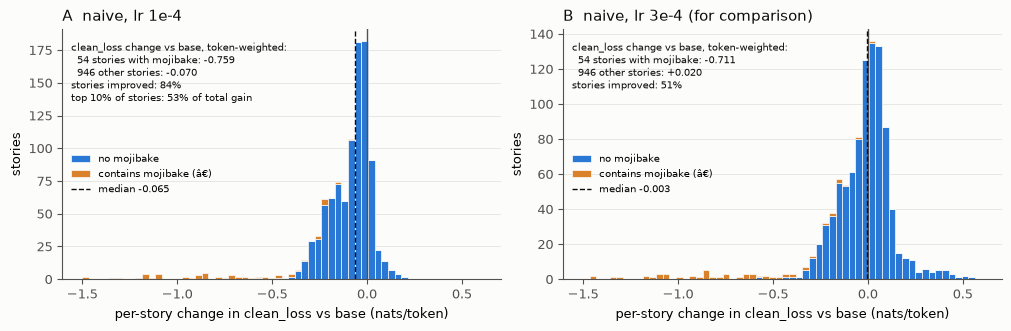

In [12]:
m = "plant_lr1e-4-naive-s0"
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True)
lo = min(ps[f"{k}_delta_loss"].min() for k in summ_ps["models"]); hi = max(ps[f"{k}_delta_loss"].max() for k in summ_ps["models"])
bins = np.linspace(np.floor(lo * 10) / 10, np.ceil(hi * 10) / 10, 61)
for a, mm, title in [(ax[0], m, "A  naive, lr 1e-4"), (ax[1], "plant_lr3e-4-naive-s0", "B  naive, lr 3e-4 (for comparison)")]:
    d = ps[f"{mm}_delta_loss"]
    a.hist([d[~ps.has_mojibake], d[ps.has_mojibake]], bins=bins, stacked=True, color=[BLUE, ORANGE],
           edgecolor=SURF, lw=0.5, label=["no mojibake", "contains mojibake (â€)"])
    a.axvline(0, color=MUTED, lw=1)
    a.axvline(np.median(d), color=INK, lw=1, ls="--", label=f"median {np.median(d):+.3f}")
    s = summ_ps["models"][mm]
    a.set_title(title, loc="left", color=INK)
    txt = (f"clean_loss change vs base, token-weighted:\n"
           f"  {s['mojibake']['n_stories']} stories with mojibake: {s['mojibake']['change']:+.3f}\n"
           f"  {s['no_mojibake']['n_stories']} other stories: {s['no_mojibake']['change']:+.3f}\n"
           f"stories improved: {100*s['frac_stories_improved']:.0f}%")
    if s["total_gain_nats"] > 0 and s["share_top10pct_stories"] <= 1:
        txt += f"\ntop 10% of stories: {100*s['share_top10pct_stories']:.0f}% of total gain"
    a.text(0.02, 0.95, txt, transform=a.transAxes, va="top", fontsize=7.5, color=INK)
    a.set_xlabel("per-story change in clean_loss vs base (nats/token)"); a.set_ylabel("stories")
    a.grid(axis="y", color=GRID, lw=0.6); a.set_axisbelow(True); a.legend(frameon=False, fontsize=7, loc="center left", bbox_to_anchor=(0, 0.42))
fig.savefig(ROOT / "reports/figures/gate2_naive_per_story.png", dpi=160)
plt.show()